# EDA: what is associated with Netflix TV series popularity

Cleaning is in `src/tmdb_tv_shows/clean.py`, the reasons are in `tmdb.ipynb`. This notebook only explores. **Assumed** means not verified.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from tmdb_tv_shows.clean import build

raw, clean, dedup, dropped = build()
netflix = dedup[dedup.is_netflix].copy()
print(len(dedup), len(netflix))   # 164705 1929

164705 1929


## 1. Scope: launched Netflix shows

- Pre-launch shows (In Production, Planned) have no votes and little history, so they are left out of the analysis.
- **Assumed:** snapshot date is 2024-04-04, the latest `last_air_date` in the data. It is not documented.

In [2]:
SNAPSHOT = pd.Timestamp("2024-04-04")

launched = netflix[netflix.first_air_date.notna() & (netflix.first_air_date <= SNAPSHOT)].copy()
print(len(netflix), len(launched))   # 1929 1773
pd.crosstab(netflix.status, netflix.index.isin(launched.index), colnames=["launched"])

1929 1773


launched,False,True
status,,
Canceled,1,206
Ended,0,949
In Production,106,40
Planned,41,1
Returning Series,8,577


## 2. Target: popularity

- Heavily skewed, so look at it raw and after `log1p`.

count    1773.00
mean       16.89
std        42.87
min         0.00
25%         3.53
50%         7.63
75%        15.70
max      1008.98
Name: popularity, dtype: float64
skew raw: 12.17 | log1p: 0.76


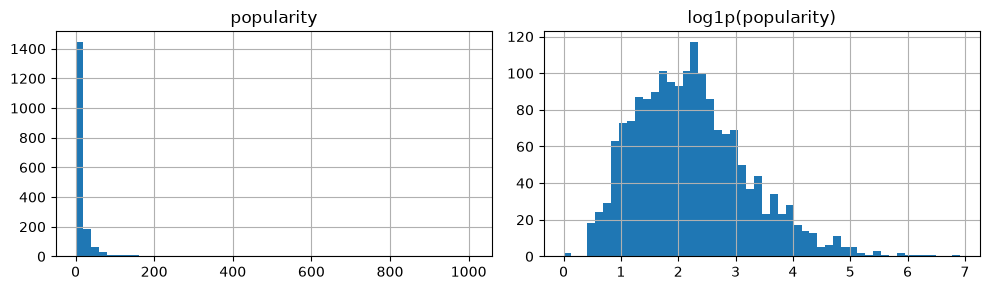

In [3]:
launched["log_pop"] = np.log1p(launched.popularity)

print(launched.popularity.describe().round(2))
print("skew raw:", round(launched.popularity.skew(), 2), "| log1p:", round(launched.log_pop.skew(), 2))

fig, ax = plt.subplots(1, 2, figsize=(10, 3))
launched.popularity.hist(bins=50, ax=ax[0]); ax[0].set_title("popularity")
launched.log_pop.hist(bins=50, ax=ax[1]); ax[1].set_title("log1p(popularity)")
plt.tight_layout()